In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Verifiko GPU dhe path-et e input-eve

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

CUDA available: True
/kaggle/input/datasets/denismustafaraj/kosovo-news-dataset-processed/val.csv
/kaggle/input/datasets/denismustafaraj/kosovo-news-dataset-processed/train.csv
/kaggle/input/datasets/denismustafaraj/kosovo-news-dataset-processed/test.csv
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/__results__.html
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/__notebook__.ipynb
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/__output__.json
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/distilbert_rezultate.json
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/custom.css
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/distilbert-results/checkpoint-4718/config.json
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/distilbert-results/checkpoint-4718/trainer_state.json
/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/distilbert-results/checkpoint-4718/training_args.bin
/kaggl

Ngarko modelin dhe tokenizer-in e trajnuar (DistilBERT)

In [2]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODEL_PATH = '/kaggle/input/notebooks/denismustafaraj/distilbert-finetuning/distilbert-final-model'
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

id2label = model.config.id2label
print("Kategoritë:", id2label)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Kategoritë: {0: 'Botë', 1: 'Ekonomi', 2: 'Kulturë', 3: 'Kuriozitete', 4: 'Lifestyle', 5: 'Politikë', 6: 'Showbiz', 7: 'Shëndet', 8: 'Sport'}


Ngarko test.csv dhe tokenizo

In [3]:
import pandas as pd
from datasets import Dataset

DATA_PATH = '/kaggle/input/datasets/denismustafaraj/kosovo-news-dataset-processed'
test_df = pd.read_csv(f'{DATA_PATH}/test.csv')

label2id = {v: k for k, v in id2label.items()}
test_df['label_id'] = test_df['label'].map(label2id)

test_ds = Dataset.from_pandas(test_df[['text_final', 'label_id']])

def tokenize_function(examples):
    return tokenizer(examples['text_final'], truncation=True, max_length=256, padding='max_length')

test_ds = test_ds.map(tokenize_function, batched=True)
test_ds = test_ds.rename_column('label_id', 'labels')
test_ds = test_ds.remove_columns(['text_final'])

print(test_ds)

Map:   0%|          | 0/16175 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 16175
})


Bëj predict (pa trajnim)

In [4]:
from transformers import Trainer
import numpy as np

trainer = Trainer(model=model)
predictions_output = trainer.predict(test_ds)

y_pred = np.argmax(predictions_output.predictions, axis=1)
y_true = predictions_output.label_ids

y_pred_labels = [id2label[i] for i in y_pred]
y_true_labels = [id2label[i] for i in y_true]

print("Predict u kompletua.")

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Predict u kompletua.


Classification Report + Confusion Matrix

Classification Report (DistilBERT, Test Set):
              precision    recall  f1-score   support

        Botë       0.89      0.87      0.88      1800
     Ekonomi       0.89      0.90      0.90      1798
     Kulturë       0.89      0.89      0.89      1798
 Kuriozitete       0.74      0.65      0.69      1798
   Lifestyle       0.73      0.65      0.69      1797
    Politikë       0.95      0.96      0.95      1799
     Showbiz       0.91      0.93      0.92      1800
     Shëndet       0.75      0.90      0.82      1800
       Sport       0.98      0.98      0.98      1785

    accuracy                           0.86     16175
   macro avg       0.86      0.86      0.86     16175
weighted avg       0.86      0.86      0.86     16175



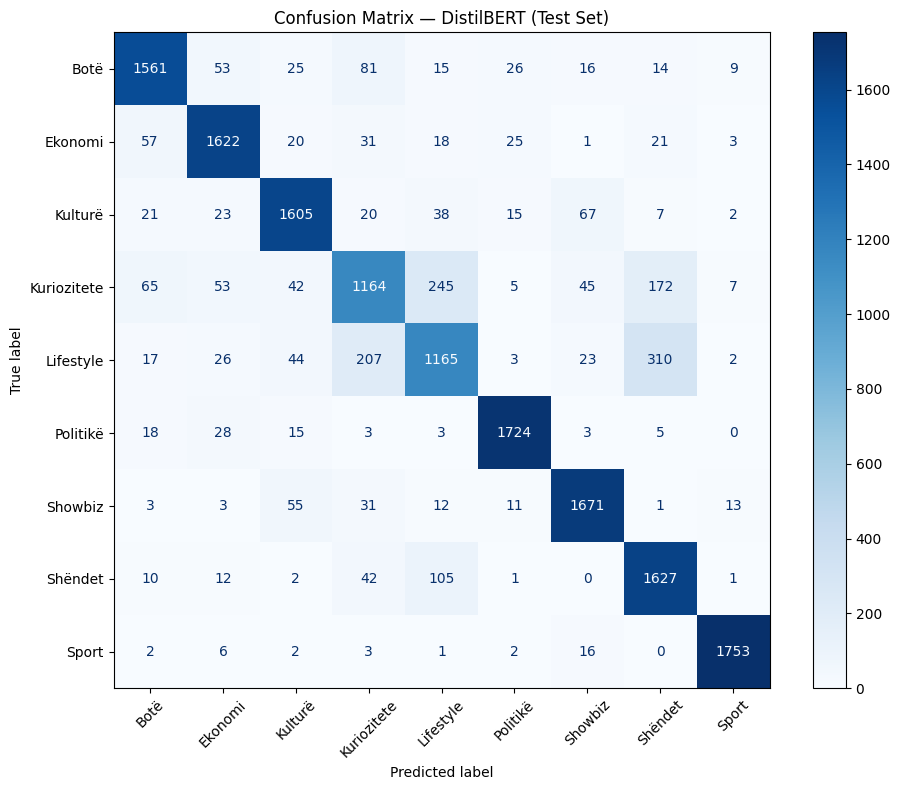

In [5]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Classification Report (DistilBERT, Test Set):")
print(classification_report(y_true_labels, y_pred_labels))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_labels, xticks_rotation=45, ax=ax, cmap='Blues')
plt.title("Confusion Matrix — DistilBERT (Test Set)")
plt.tight_layout()
plt.savefig('/kaggle/working/distilbert_confusion_matrix.png', dpi=150)
plt.show()

Ruajtja e rezultateve finale

In [6]:
import json

distilbert_test_final = {
    'model': 'distilbert-base-multilingual-cased',
    'test_accuracy': 0.86,
    'test_f1_macro': 0.86,
    'per_class_f1': {
        'Botë': 0.88, 'Ekonomi': 0.90, 'Kulturë': 0.89,
        'Kuriozitete': 0.69, 'Lifestyle': 0.69, 'Politikë': 0.95,
        'Showbiz': 0.92, 'Shëndet': 0.82, 'Sport': 0.98
    }
}

with open('/kaggle/working/distilbert_test_final.json', 'w') as f:
    json.dump(distilbert_test_final, f, indent=2)

print("Rezultatet finale u ruajtën.")

Rezultatet finale u ruajtën.
